guys first we need to light cleaning standardization 

- [x] Jupyter notebook — data wrangling and ML code, markdown commentary, and outputs, running endto\-end without errors\.

- [x] Cleaning & transformation log — can be embedded in the notebook as markdown or submitted as a short separate document\.

- [ ] Power BI file \(\.pbix\) — dashboard connected to final dataset/model outputs, plus a PDF export as a fallback\.

- [ ] Written report \(5–7 pages\) — objective, dataset description, methodology per pipeline stage, ML approach and results, dashboard walkthrough, insights, limitations\. Word or PDF\.

- [ ] Presentation deck \(8–10 slides\) for the viva, including a live or screen\-recorded dashboard demo\.

- [ ] Raw and cleaned dataset files \(or a script to regenerate them, if the raw file is too large to submit\)\.

- [ ] Individual contribution statement — one line per member describing their primary responsibility

4\.1 Data Extraction
• Document how and from where the data was obtained \(download, API call, scrape, or DB query\)\.
• Note any access constraints, rate limits, authentication, or licensing terms encountered\.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata

In [37]:
# =========================================================
# Global cleaning log helper — usable across all stages
# =========================================================
cleaning_log_rows = []   # list of dicts

def log_step(city, column, action, detail, rows=None):
    cleaning_log_rows.append({
        "city":   city,
        "column": column,
        "action": action,
        "detail": detail,
        "rows":   rows,
    })

In [2]:
df_nyc_l = pd.read_csv("/work/NYC/NYC/listings.csv") #Listing
df_nyc_c = pd.read_csv("/work/NYC/NYC/calendar.csv") #Calendar
df_nyc_n = pd.read_csv("/work/NYC/NYC/neighbourhoods.csv") #Neighbourhoods
df_nyc_r = pd.read_csv("/work/NYC/NYC/reviews.csv") #Reviews

In [3]:
df_la_l = pd.read_csv("/work/20260903-025654/LA/listings.csv") #Listing
df_la_c = pd.read_csv("/work/20260903-025654/LA/calendar.csv") #Calendar
df_la_n = pd.read_csv("/work/20260903-025654/LA/neighbourhoods.csv") #Neighbourhoods
df_la_r = pd.read_csv("/work/20260903-025654/LA/reviews.csv") #Reviews

In [4]:
print("Neighbourhood:", df_nyc_n.shape, df_la_n.shape)
print("Calendar:", df_nyc_c.shape, df_la_c.shape)
print("Reviews:", df_nyc_r.shape, df_la_r.shape)
print("Listing:", df_nyc_l.shape, df_la_l.shape)

Neighbourhood: (230, 2) (270, 2)
Calendar: (11035410, 5) (16035198, 5)
Reviews: (994127, 6) (1856294, 6)
Listing: (30234, 90) (43781, 90)


In [5]:
print("NY")
print("Neighbourhood:\n", df_nyc_n.info())
print("Calendar:\n", df_nyc_c.info())
print("Reviews:\n", df_nyc_r.info())
print("Listing:\n", df_nyc_l.info())

print("\nLA")
print("Neighbourhood:\n", df_la_n.info())
print("Calendar:\n", df_la_c.info())
print("Reviews:\n", df_la_r.info())
print("Listing:\n", df_la_l.info())

NY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 230 entries, 0 to 229
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   neighbourhood_group  230 non-null    object
 1   neighbourhood        230 non-null    object
dtypes: object(2)
memory usage: 3.7+ KB
Neighbourhood:
 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11035410 entries, 0 to 11035409
Data columns (total 5 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   listing_id      int64 
 1   date            object
 2   available       object
 3   minimum_nights  int64 
 4   maximum_nights  int64 
dtypes: int64(3), object(2)
memory usage: 421.0+ MB
Calendar:
 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994127 entries, 0 to 994126
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   listing_id     994127 non-null  int64 
 1   id         

4\.2 Data Cleaning
• Handle missing values, duplicates, type mismatches, and inconsistent categorical labels with justification 
for the method chosen \(drop vs\. impute vs\. flag\), not just the code\.
• Maintain a short cleaning log: what was found, what was done, what was left as\-is and why

In [6]:
def missing_value_report(city, neighbourhood, calendar, reviews, listings):
    dataframes = {
        "Neighbourhood": neighbourhood,
        "Calendar": calendar,
        "Reviews": reviews,
        "Listings": listings
    }
    print(f"\n{'='*15} {city} {'='*15}")
    for name, df in dataframes.items():
        print(f"\n{name}:")
        missing_percentage = (df.isnull().sum() / len(df)) * 100
        print(missing_percentage[missing_percentage > 0].round(2).sort_values(ascending=False))

In [7]:
missing_value_report(
    "NYC",
    df_nyc_n,
    df_nyc_c,
    df_nyc_r,
    df_nyc_l
)

missing_value_report(
    "LA",
    df_la_n,
    df_la_c,
    df_la_r,
    df_la_l
)


=============== NYC ===============

Neighbourhood:
Series([], dtype: float64)

Calendar:
Series([], dtype: float64)

Reviews:
comments         0.03
reviewer_name    0.00
dtype: float64

Listings:
neighborhood_overview          100.00
host_since                     100.00
host_neighbourhood             100.00
host_verifications             100.00
host_total_listings_count      100.00
host_thumbnail_url             100.00
host_response_time             100.00
host_acceptance_rate           100.00
host_response_rate             100.00
calendar_updated               100.00
instant_bookable               100.00
neighbourhood                  100.00
license                         82.74
host_about                      41.30
bedrooms                        41.23
bathrooms                       34.31
price_quote_price_per_night     32.79
price_quote_total_price         32.79
estimated_revenue_l365d         32.75
price                           32.75
beds                            32.33
revi

In [8]:
print("NYC Duplicates:\n")
print("Neighbourhood Count:", df_nyc_n.duplicated().sum())
print("Calendar Count:     ", df_nyc_c.duplicated().sum())
print("Reviews Count:      ", df_nyc_r.duplicated().sum())
print("Listing Count:      ", df_nyc_l.duplicated().sum())

print("\nLA Duplicates:\n")
print("Neighbourhood Count:", df_la_n.duplicated().sum())
print("Calendar Count:     ", df_la_c.duplicated().sum())
print("Reviews Count:      ", df_la_r.duplicated().sum())
print("Listing Count:      ", df_la_l.duplicated().sum())

print("Duplicate Listing IDs in NYC:", df_nyc_l.duplicated(subset=['id']).sum())
print("Duplicate Listing IDs in LA: ", df_la_l.duplicated(subset=['id']).sum())

NYC Duplicates:

Neighbourhood Count: 0
Calendar Count:      0
Reviews Count:       0
Listing Count:       0

LA Duplicates:

Neighbourhood Count: 0
Calendar Count:      0
Reviews Count:       0
Listing Count:       0
Duplicate Listing IDs in NYC: 0
Duplicate Listing IDs in LA:  0


In [9]:
#checking for differing columns 
nyc_only = set(df_nyc_l.columns) - set(df_la_l.columns)
la_only  = set(df_la_l.columns)  - set(df_nyc_l.columns)
print("NYC-only:", sorted(nyc_only))
print("LA-only:",  sorted(la_only))

NYC-only: []
LA-only: []


In [10]:
#verifying schema
# Are they byte-for-byte identical schemas?
print("Same column order:", list(df_nyc_l.columns) == list(df_la_l.columns))
print("Same column set: ", set(df_nyc_l.columns) == set(df_la_l.columns))

# Now check dtype mismatches
nyc_dtypes = df_nyc_l.dtypes.astype(str)
la_dtypes  = df_la_l.dtypes.astype(str)
mismatch = (nyc_dtypes != la_dtypes)
print("\nDtype mismatches:")
print(pd.DataFrame({
    "NYC": nyc_dtypes[mismatch],
    "LA":  la_dtypes[mismatch],
}))

print(f"\nShapes — NYC: {df_nyc_l.shape}, LA: {df_la_l.shape}")

Same column order: True
Same column set:  True

Dtype mismatches:
                               NYC     LA
host_profile_id            float64  int64
hosts_time_as_user_years   float64  int64
hosts_time_as_user_months  float64  int64
hosts_time_as_host_years   float64  int64
hosts_time_as_host_months  float64  int64
host_listings_count        float64  int64

Shapes — NYC: (30234, 90), LA: (43781, 90)


In [11]:
def clean_listings(df, city_name, log=None):
    if log is None:
        log = []
    def _log(col, action, detail, n=None):
        log.append({"city": city_name, "column": col,
                    "action": action, "detail": detail, "rows": n})
    df = df.copy()

    # ---- 1. Price to numeric
    if "price" in df.columns:
        n0 = df["price"].isna().sum()
        df["price"] = pd.to_numeric(
            df["price"].astype("string").str.replace(r"[$,]", "", regex=True),
            errors="coerce"
        )
        _log("price", "type_convert", "Strip $/,, cast float",
             df["price"].isna().sum() - n0)

    # ---- 2. Numeric coercion
    numeric_cols = [
        "calculated_host_listings_count", "minimum_nights", "maximum_nights",
        "bedrooms", "beds", "bathrooms", "accommodates",
        "availability_365", "availability_30", "availability_60", "availability_90",
        "number_of_reviews", "reviews_per_month",
        "review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
        "review_scores_checkin", "review_scores_communication",
        "review_scores_location", "review_scores_value",
        "host_profile_id", "host_listings_count",
        "hosts_time_as_user_years", "hosts_time_as_user_months",
        "hosts_time_as_host_years", "hosts_time_as_host_months",
    ]
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # ---- 3. Boolean coercion for host_is_superhost
    if "host_is_superhost" in df.columns:
        s = df["host_is_superhost"].astype("string").str.strip().str.lower()
        bool_map = {"t": True, "true": True, "1": True, "yes": True,
                    "f": False, "false": False, "0": False, "no": False}
        df["host_is_superhost"] = s.map(bool_map).astype("boolean")
        _log("host_is_superhost", "bool_cast",
             "t/f → True/False (nullable boolean)")

    # ---- 4. Flag missingness BEFORE imputing
    flag_cols = [
        "license", "reviews_per_month", "last_review", "price",
        "host_profile_id", "host_name", "host_id",
        "calculated_host_listings_count", "minimum_nights",
        "bedrooms", "beds", "bathrooms", "review_scores_rating",
    ]
    for col in flag_cols:
        if col in df.columns:
            df[col + "_was_missing"] = df[col].isna().astype(int)
            _log(col, "flag_missing", f"{col}_was_missing",
                 df[col].isna().sum())

    # ---- 5. Impute numerics with median
    '''for col in ["price", "calculated_host_listings_count", "minimum_nights"]:
        if col in df.columns:
            n = df[col].isna().sum()
            med = df[col].median()
            df[col] = df[col].fillna(med)
            _log(col, "impute_median", f"median={med:.2f}", n)'''

    # ---- 6. reviews_per_month conditional
    if {"number_of_reviews", "reviews_per_month"}.issubset(df.columns):
        no_rev = df["number_of_reviews"].eq(0)
        has_rev = df["number_of_reviews"] > 0

        n0 = (no_rev & df["reviews_per_month"].isna()).sum()
        df.loc[no_rev & df["reviews_per_month"].isna(),
               "reviews_per_month"] = 0
        _log("reviews_per_month", "impute_zero", "0 where reviews==0", n0)

        med_rpm = df.loc[has_rev, "reviews_per_month"].median()
        n1 = (has_rev & df["reviews_per_month"].isna()).sum()
        df.loc[has_rev & df["reviews_per_month"].isna(),
               "reviews_per_month"] = med_rpm
        _log("reviews_per_month", "impute_median",
             f"median={med_rpm:.2f}", n1)

        df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

    # ---- 7. Categorical to "Not available"
    for col in ["host_profile_id", "host_name", "license"]:
        if col in df.columns:
            n = df[col].isna().sum()
            df[col] = df[col].fillna("Not available")
            _log(col, "impute_constant", "'Not available'", n)

    # ---- 8. Dates to datetime (NaT preserved)
    for col in ["last_review", "first_review",
                "last_scraped", "calendar_last_scraped"]:
        if col in df.columns:
            n = df[col].isna().sum()
            df[col] = pd.to_datetime(df[col], errors="coerce")
            _log(col, "type_convert", "datetime; NaT preserved", n)

    # ---- 9. license_category
    if "license" in df.columns:
        def _cat(val):
            if pd.isna(val):
                return "Missing"
            s = str(val).strip().lower()
            if s in ("not available", "not_available", "nan", "", "none"):
                return "Missing"
            if s.startswith("exempt"):
                return "Exempt"
            return "Registered"

        df["license_category"] = df["license"].apply(_cat)
        _log("license", "categorize", "Missing/Exempt/Registered")

    # ---- 10. Text normalization
    def _norm(s):
        if pd.isna(s):
            return s
        s = unicodedata.normalize("NFKC", str(s)).replace("\u200b", "")
        return re.sub(r"\s+", " ", s).strip()

    for col in ["room_type", "neighbourhood", "neighbourhood_group",
                "property_type", "host_name", "source"]:
        if col in df.columns:
            df[col] = df[col].apply(_norm)

    # ---- 11. Rename cleansed to canonical
    if "neighbourhood" in df.columns and "neighbourhood_cleansed" in df.columns:
        if df["neighbourhood"].isna().all():
            df = df.drop(columns=["neighbourhood"])
        else:
            df = df.drop(columns=["neighbourhood_cleansed"])

    if "neighbourhood_group" in df.columns and "neighbourhood_group_cleansed" in df.columns:
        if df["neighbourhood_group"].isna().all():
            df = df.drop(columns=["neighbourhood_group"])
        else:
            df = df.drop(columns=["neighbourhood_group_cleansed"])

    df = df.rename(columns={
        "neighbourhood_cleansed":       "neighbourhood",
        "neighbourhood_group_cleansed": "neighbourhood_group",
    })

    # ---- 12. City tag
    df["city"] = city_name

    return df, log

In [12]:
df_nyc_l_clean, log_nyc = clean_listings(df_nyc_l, "NYC")
df_la_l_clean,  log_la  = clean_listings(df_la_l,  "LA")
cleaning_log = pd.DataFrame(log_nyc + log_la)

print(f"NYC: {df_nyc_l_clean.shape}")
print(f"LA:  {df_la_l_clean.shape}")
print(f"Log entries: {len(cleaning_log)}")

NYC: (30234, 104)
LA:  (43781, 104)
Log entries: 50


In [13]:
#manual drop 
manual_drop = ["bathrooms", "bathrooms_was_missing",
               "price_quote_raw", "scrape_id"]

for df in [df_nyc_l_clean, df_la_l_clean]:
    cols_to_drop = [c for c in manual_drop if c in df.columns]
    print(f"Dropping: {cols_to_drop}")
    df.drop(columns=cols_to_drop, inplace=True, errors="ignore")

print("NYC shape:", df_nyc_l_clean.shape)
print("LA  shape:", df_la_l_clean.shape)

Dropping: ['bathrooms', 'bathrooms_was_missing', 'price_quote_raw', 'scrape_id']
Dropping: ['bathrooms', 'bathrooms_was_missing', 'price_quote_raw', 'scrape_id']
NYC shape: (30234, 100)
LA  shape: (43781, 100)


In [14]:
#checking for duplicated cols across both datasets
for name, d in [("NYC", df_nyc_l_clean), ("LA", df_la_l_clean)]:
    neigh_cols = [c for c in d.columns if "neighbour" in c.lower()]
    dupes = d.columns[d.columns.duplicated()].tolist()
    print(f"{name}:")
    print(f"  shape: {d.shape}")
    print(f"  neighbour columns: {neigh_cols}")
    print(f"  duplicate columns: {dupes if dupes else 'none '}")
    print(f"  neighbourhood missing%: {d['neighbourhood'].isna().mean()*100:.2f}")
    print()

NYC:
  shape: (30234, 100)
  neighbour columns: ['host_neighbourhood', 'neighbourhood', 'neighbourhood_group']
  duplicate columns: none 
  neighbourhood missing%: 0.00

LA:
  shape: (43781, 100)
  neighbour columns: ['host_neighbourhood', 'neighbourhood', 'neighbourhood_group']
  duplicate columns: none 
  neighbourhood missing%: 0.00



In [15]:
#dropping cols which has 100% missing values
empty_nyc = {c for c in df_nyc_l_clean.columns
             if df_nyc_l_clean[c].isna().all()}
empty_la  = {c for c in df_la_l_clean.columns
             if df_la_l_clean[c].isna().all()}
drop_both = sorted(empty_nyc & empty_la)

print(f"Dropping {len(drop_both)} cols 100%-empty in both:")
for c in drop_both:
    print(f"  {c}")

df_nyc_l_clean.drop(columns=drop_both, inplace=True, errors="ignore")
df_la_l_clean.drop(columns=drop_both,  inplace=True, errors="ignore")

print(f"\nNYC: {df_nyc_l_clean.shape}")
print(f"LA:  {df_la_l_clean.shape}")

Dropping 11 cols 100%-empty in both:
  calendar_updated
  host_acceptance_rate
  host_neighbourhood
  host_response_rate
  host_response_time
  host_since
  host_thumbnail_url
  host_total_listings_count
  host_verifications
  instant_bookable
  neighborhood_overview

NYC: (30234, 89)
LA:  (43781, 89)


In [16]:
#checking for shared cols and calculating missing values
shared_cols = sorted(set(df_nyc_l_clean.columns) & set(df_la_l_clean.columns))
print(f"shared_cols: {len(shared_cols)}")

nyc = df_nyc_l_clean[shared_cols].copy()
la  = df_la_l_clean[shared_cols].copy()

df_all = pd.concat([nyc, la], ignore_index=True)

# Compound key
assert "neighbourhood" in df_all.columns
assert df_all["neighbourhood"].isna().mean() < 0.05, "neighbourhood mostly empty!"

df_all["city_neighbourhood"] = (
    df_all["city"].astype(str) + " — " + df_all["neighbourhood"].astype(str)
)

# Boolean
if df_all["host_is_superhost"].dtype.name != "boolean":
    s = df_all["host_is_superhost"].astype("string").str.strip().str.lower()
    df_all["host_is_superhost"] = s.map(
        {"t": True, "true": True, "1": True,
         "f": False, "false": False, "0": False}
    ).astype("boolean")

# Report
print(f"\n df_all: {df_all.shape}")
print(f"Cities: {df_all['city'].value_counts().to_dict()}")
print(f"Keys:   {df_all['city_neighbourhood'].nunique()}")
print(f"neighbourhood missing%: {df_all['neighbourhood'].isna().mean()*100:.2f}")

# Missingness snapshot
miss = df_all.isna().sum()
pct  = (miss / len(df_all) * 100).round(2)
print("\nRemaining missing values:")
print(pd.DataFrame({"count": miss, "percent": pct})
        .query("count > 0")
        .sort_values("percent", ascending=False))

shared_cols: 89

 df_all: (74015, 90)
Cities: {'LA': 43781, 'NYC': 30234}
Keys:   487
neighbourhood missing%: 0.00

Remaining missing values:
                             count  percent
source                       37507    50.67
host_about                   31310    42.30
review_scores_checkin        19170    25.90
review_scores_location       19172    25.90
review_scores_value          19173    25.90
review_scores_communication  19162    25.89
review_scores_cleanliness    19159    25.89
review_scores_accuracy       19165    25.89
first_review                 19154    25.88
review_scores_rating         19154    25.88
last_review                  19154    25.88
host_location                18374    24.82
price_quote_price_per_night  17017    22.99
price_quote_total_price      17017    22.99
price                        16997    22.96
estimated_revenue_l365d      16997    22.96
price_quote_checkout_date    12810    17.31
price_quote_checkin_date     12810    17.31
bedrooms              

In [17]:
# ---- Assertions
assert df_all.shape[0] == 74015, f"Row count: {df_all.shape[0]}"
assert set(df_all["city"]) == {"NYC", "LA"}, "City labels wrong"
assert df_all.duplicated(subset=["id"]).sum() == 0, "Duplicate ids!"
assert df_all["price"].dtype.kind == "f", "price not float"
assert df_all["last_review"].dtype.kind == "M", "last_review not datetime"
assert "bathrooms" not in df_all.columns, "bathrooms should be dropped"
assert df_all["license_category"].isna().sum() == 0, "license_category has NaN"
assert df_all["host_is_superhost"].dtype.name == "boolean", "superhost not boolean"

all_empty = [c for c in df_all.columns if df_all[c].isna().all()]
assert not all_empty, f"100%-empty columns remain: {all_empty}"

print(" All assertions passed")
print(f"Shape:  {df_all.shape}")
print(f"Cities: {df_all['city'].value_counts().to_dict()}")
print(f"Keys:   {df_all['city_neighbourhood'].nunique()}")

# ---- Superhost by city (headline insight candidate)
sh = (df_all.groupby("city")["host_is_superhost"]
            .value_counts(normalize=True, dropna=False)
            .mul(100).round(2)
            .unstack(fill_value=0))
print("\nSuperhost rate by city (%):")
print(sh)

print("\nAbsolute counts:")
print(pd.crosstab(df_all["city"], df_all["host_is_superhost"], dropna=False))

 All assertions passed
Shape:  (74015, 90)
Cities: {'LA': 43781, 'NYC': 30234}
Keys:   487

Superhost rate by city (%):
host_is_superhost  False  True   <NA> 
city                                  
LA                 61.36  38.64    0.0
NYC                77.03  21.11   1.86

Absolute counts:
host_is_superhost  False  True   <NA> 
city                                  
LA                 26864  16917      0
NYC                23289   6382    563


In [18]:
# ---- Render cleaning log as a table
print("=" * 60)
print("CLEANING LOG")
print("=" * 60)
display(
    cleaning_log
    .sort_values(["city", "action", "column"])
    .reset_index(drop=True)
)

# Save for the report
cleaning_log.to_csv("/work/cleaning_log.csv", index=False)
print(f"\nSaved {len(cleaning_log)} log entries to /work/cleaning_log.csv")

# Summary counts
print("\nActions per city:")
print(cleaning_log.groupby(["city", "action"]).size().unstack(fill_value=0))

CLEANING LOG


,city,column,action,detail,rows
0,LA,host_is_superhost,bool_cast,t/f → True/False (nullable boolean),NaN
1,LA,license,categorize,Missing/Exempt/Registered,NaN
2,LA,bathrooms,flag_missing,bathrooms_was_missing,43781.0
3,LA,bedrooms,flag_missing,bedrooms_was_missing,90.0
4,LA,beds,flag_missing,beds_was_missing,1077.0
5,LA,calculated_host_listings_count,flag_missing,calculated_host_listings_count_was_missing,0.0
6,LA,host_id,flag_missing,host_id_was_missing,0.0
7,LA,host_name,flag_missing,host_name_was_missing,0.0
8,LA,host_profile_id,flag_missing,host_profile_id_was_missing,0.0
9,LA,last_review,flag_missing,last_review_was_missing,10845.0



Saved 50 log entries to /work/cleaning_log.csv

Actions per city:
action  bool_cast  categorize  flag_missing  impute_constant  impute_median  \
city                                                                          
LA              1           1            13                3              1   
NYC             1           1            13                3              1   

action  impute_zero  type_convert  
city                               
LA                1             5  
NYC               1             5  


In [19]:
# ---- Final cleaning verification — cite these in the report
print("=" * 60)
print("CLEANING VERIFICATION")
print("=" * 60)

print(f"\n1. Row counts preserved:")
print(f"   NYC raw → clean:  {len(df_nyc_l)} → {len(df_nyc_l_clean)}")
print(f"   LA  raw → clean:  {len(df_la_l)}  → {len(df_la_l_clean)}")

print(f"\n2. Schema symmetry:")
print(f"   NYC cols: {len(df_nyc_l_clean.columns)}")
print(f"   LA  cols: {len(df_la_l_clean.columns)}")
print(f"   Match: {set(df_nyc_l_clean.columns) == set(df_la_l_clean.columns)}")

print(f"\n3. Duplicate ids in df_all: {df_all['id'].duplicated().sum()}")

print(f"\n4. Dtypes check:")
print(f"   price:                {df_all['price'].dtype}")
print(f"   last_review:          {df_all['last_review'].dtype}")
print(f"   host_is_superhost:    {df_all['host_is_superhost'].dtype}")

print(f"\n5. Remaining missingness (genuine only):")
miss = df_all.isna().sum()
pct  = (miss / len(df_all) * 100).round(2)
print(pd.DataFrame({"count": miss, "percent": pct})
        .query("count > 0")
        .sort_values("percent", ascending=False))

print(f"\n6. Cleaning log entries: {len(cleaning_log)}")

CLEANING VERIFICATION

1. Row counts preserved:
   NYC raw → clean:  30234 → 30234
   LA  raw → clean:  43781  → 43781

2. Schema symmetry:
   NYC cols: 89
   LA  cols: 89
   Match: True

3. Duplicate ids in df_all: 0

4. Dtypes check:
   price:                Float64
   last_review:          datetime64[ns]
   host_is_superhost:    boolean

5. Remaining missingness (genuine only):
                             count  percent
source                       37507    50.67
host_about                   31310    42.30
review_scores_checkin        19170    25.90
review_scores_location       19172    25.90
review_scores_value          19173    25.90
review_scores_communication  19162    25.89
review_scores_cleanliness    19159    25.89
review_scores_accuracy       19165    25.89
first_review                 19154    25.88
review_scores_rating         19154    25.88
last_review                  19154    25.88
host_location                18374    24.82
price_quote_price_per_night  17017    22.99


4\.3 Data Transformation
• At least one non\-trivial reshape or aggregation \(pivot, group by, merge/join across tables, or timebased/recency aggregation\)\.
• At least one engineered/derived feature that supports the analysis question\.

In [20]:
print("=" * 60)
print("REVIEWS")
print("=" * 60)
for name, df in [("NYC", df_nyc_r), ("LA", df_la_r)]:
    print(f"\n{name}: shape={df.shape}")
    print(f"  columns: {df.columns.tolist()}")
    print(f"  date dtype: {df['date'].dtype}")

print("\n" + "=" * 60)
print("CALENDAR")
print("=" * 60)
for name, df in [("NYC", df_nyc_c), ("LA", df_la_c)]:
    print(f"\n{name}: shape={df.shape}")
    print(f"  columns: {df.columns.tolist()}")
    print(f"  date dtype: {df['date'].dtype}")
    print(f"  available values: {df['available'].value_counts().to_dict()}")
    print(f"  date range: {df['date'].min()} → {df['date'].max()}")

print("\n" + "=" * 60)
print("SAMPLE CALENDAR ROWS")
print("=" * 60)
display(df_nyc_c.head(3))
#date didnt change to datetime so we first fix that, it is still object

REVIEWS

NYC: shape=(994127, 6)
  columns: ['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']
  date dtype: object

LA: shape=(1856294, 6)
  columns: ['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']
  date dtype: object

CALENDAR

NYC: shape=(11035410, 5)
  columns: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
  date dtype: object
  available values: {'t': 5746037, 'f': 5289373}
  date range: 2026-08-10 → 2027-08-20

LA: shape=(16035198, 5)
  columns: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
  date dtype: object
  available values: {'t': 9834629, 'f': 6200569}
  date range: 2026-06-15 → 2027-06-22

SAMPLE CALENDAR ROWS


,listing_id,date,available,minimum_nights,maximum_nights
0,2539,2026-08-11,t,30,730
1,2539,2026-08-12,t,30,730
2,2539,2026-08-13,t,30,730


In [21]:
#converting dates to date time
for df in [df_nyc_r, df_la_r, df_nyc_c, df_la_c]:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Dates converted")
for name, df in [("NYC r", df_nyc_r), ("LA r", df_la_r),
                 ("NYC c", df_nyc_c), ("LA c", df_la_c)]:
    print(f"  {name}: {df['date'].dtype}")

Dates converted
  NYC r: datetime64[ns]
  LA r: datetime64[ns]
  NYC c: datetime64[ns]
  LA c: datetime64[ns]


In [22]:
#review aggregation
reviews = pd.concat([
    df_nyc_r[["listing_id", "date"]].assign(city="NYC"),
    df_la_r[["listing_id", "date"]].assign(city="LA"),
], ignore_index=True)

as_of = reviews["date"].max()
print(f"As-of date: {as_of.date()}")

#per listing aggregation
reviews_agg = (
    reviews.groupby("listing_id")
    .agg(
        reviews_total      = ("date", "count"),
        reviews_last_date  = ("date", "max"),
    )
    .reset_index()
    .rename(columns={"listing_id": "id"})
)

#time-based recency 
reviews_agg["reviews_last_90d"] = (
    reviews[reviews["date"] >= as_of - pd.Timedelta(days=90)]
    .groupby("listing_id").size()
    .reindex(reviews_agg["id"]).fillna(0).astype(int).values
)
reviews_agg["reviews_last_365d"] = (
    reviews[reviews["date"] >= as_of - pd.Timedelta(days=365)]
    .groupby("listing_id").size()
    .reindex(reviews_agg["id"]).fillna(0).astype(int).values
)
reviews_agg["review_recency_days"] = (
    as_of - reviews_agg["reviews_last_date"]
).dt.days

print(f"reviews_agg: {reviews_agg.shape}")

print(f"\nShape: {reviews_agg.shape}")
print(f"Columns: {reviews_agg.columns.tolist()}")

print(f"\nAs-of date: {as_of.date()}")
print(f"Total reviews across both cities: {len(reviews):,}")
print(f"Unique listings in reviews: {reviews['listing_id'].nunique():,}")
print(f"Unique listings in agg:     {reviews_agg['id'].nunique():,}")

# Sanity: total reviews should equal sum of reviews_total
total_check = reviews_agg["reviews_total"].sum()
print(f"\nSum of reviews_total: {total_check:,}")
print(f"Match total reviews:  {total_check == len(reviews)}")

# Numeric summary
print("\nNumeric summary of aggregated features:")
display(
    reviews_agg[["reviews_total", "reviews_last_90d",
                 "reviews_last_365d", "review_recency_days"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95])
    .round(2)
)

# Consistency checks
print("\nConsistency checks:")
print(f"  reviews_last_90d  <= reviews_last_365d: "
      f"{(reviews_agg['reviews_last_90d'] <= reviews_agg['reviews_last_365d']).all()}")
print(f"  reviews_last_365d <= reviews_total:     "
      f"{(reviews_agg['reviews_last_365d'] <= reviews_agg['reviews_total']).all()}")
print(f"  Any null reviews_total?                 "
      f"{reviews_agg['reviews_total'].isna().any()}")
print(f"  Any negative recency_days?              "
      f"{(reviews_agg['review_recency_days'] < 0).any()}")

# Distribution preview
print("\nSample rows:")
display(reviews_agg.head(5))

# Zero-recency listings — listings whose last review was the as-of date
n_zero = (reviews_agg["review_recency_days"] == 0).sum()
print(f"\nListings whose last review = as-of date: {n_zero:,}")

# Listings with no recent reviews
print(f"Listings with 0 reviews in last 90d:  "
      f"{(reviews_agg['reviews_last_90d'] == 0).sum():,}")
print(f"Listings with 0 reviews in last 365d: "
      f"{(reviews_agg['reviews_last_365d'] == 0).sum():,}")

As-of date: 2026-08-20
reviews_agg: (54546, 6)

Shape: (54546, 6)
Columns: ['id', 'reviews_total', 'reviews_last_date', 'reviews_last_90d', 'reviews_last_365d', 'review_recency_days']

As-of date: 2026-08-20
Total reviews across both cities: 2,850,421
Unique listings in reviews: 54,546
Unique listings in agg:     54,546

Sum of reviews_total: 2,850,421
Match total reviews:  True

Numeric summary of aggregated features:


,reviews_total,reviews_last_90d,reviews_last_365d,review_recency_days
count,54546.00,54546.00,54546.00,54546.00
mean,52.26,1.17,8.27,658.16
std,98.73,4.75,18.97,945.91
min,1.00,0.00,0.00,0.00
25%,4.00,0.00,0.00,81.00
50%,15.00,0.00,1.00,179.00
75%,58.00,1.00,9.00,899.00
95%,226.00,5.00,39.00,2910.00
max,4735.00,383.00,1120.00,5579.00



Consistency checks:
  reviews_last_90d  <= reviews_last_365d: True
  reviews_last_365d <= reviews_total:     True
  Any null reviews_total?                 False
  Any negative recency_days?              False

Sample rows:


,id,reviews_total,reviews_last_date,reviews_last_90d,reviews_last_365d,review_recency_days
0,2539,10,2026-05-28,1,1,84
1,2708,47,2026-05-26,1,2,86
2,2732,24,2022-08-21,0,0,1460
3,6033,19,2020-03-22,0,0,2342
4,6848,199,2026-06-30,1,4,51



Listings whose last review = as-of date: 1
Listings with 0 reviews in last 90d:  36,057
Listings with 0 reviews in last 365d: 20,827


In [39]:
# ---- 4.3 log: reviews aggregation
log_step("both", "*", "aggregate",
         "Reviews table (2,850,421 rows) aggregated by listing_id → "
         "reviews_total, reviews_last_90d, reviews_last_365d, review_recency_days",
         rows=len(reviews))
log_step("both", "reviews_last_90d", "time_window",
         "Reviews from last 90 days (as_of = 2026-08-20)")
log_step("both", "reviews_last_365d", "time_window",
         "Reviews from last 365 days")
log_step("both", "review_recency_days", "derived",
         "Days since last review (as_of date − last_review_date)")
print(f"Logged 4 entries for reviews aggregation")

Logged 4 entries for reviews aggregation


In [23]:
# Calendar occupancy aggregation
# ---- 1. Make sure date columns are datetimes on BOTH calendars
for df_c in [df_nyc_c, df_la_c]:
    df_c["date"] = pd.to_datetime(df_c["date"], errors="coerce")

# ---- 2. Aggregate calendar to one row per listing, per city
def aggregate_calendar(df_c):
    agg = (
        df_c.assign(is_booked=df_c["available"].eq("f").astype(int))
           .groupby("listing_id")
           .agg(
               cal_days           = ("date", "count"),
               cal_booked_days    = ("is_booked", "sum"),
               cal_min_min_nights = ("minimum_nights", "min"),
               cal_max_max_nights = ("maximum_nights", "max"),
               cal_first_date     = ("date", "min"),
               cal_last_date      = ("date", "max"),
           )
           .reset_index()
    )
    agg["cal_occupancy_rate"] = (
    agg["cal_booked_days"] / agg["cal_days"].replace(0, pd.NA)
).round(4)
    return agg

cal_nyc = aggregate_calendar(df_nyc_c)
cal_la  = aggregate_calendar(df_la_c)

cal_all = pd.concat([cal_nyc, cal_la], ignore_index=True)

# ---- 3. Merge into df_all
df_all = df_all.merge(
    cal_all,
    left_on="id", right_on="listing_id",
    how="left",
).drop(columns="listing_id")

# ---- 4. Sanity check
print("df_all shape after calendar merge:", df_all.shape)

print("\nNew calendar columns:")
print(df_all[[
    "cal_days", "cal_booked_days", "cal_occupancy_rate",
    "cal_min_min_nights", "cal_max_max_nights",
]].describe().round(2))

print("\nMissing rate of new columns (%):")
new_cols = ["cal_days", "cal_booked_days", "cal_occupancy_rate",
            "cal_min_min_nights", "cal_max_max_nights",
            "cal_first_date", "cal_last_date"]
print((df_all[new_cols].isna().mean() * 100).round(2))

print("\nCalendar date ranges per city:")
for name, df_c in [("NYC", df_nyc_c), ("LA", df_la_c)]:
    print(f"  {name}: {df_c['date'].min().date()} → {df_c['date'].max().date()} "
          f"({df_c['date'].dt.normalize().nunique()} unique days)")

df_all shape after calendar merge: (74015, 97)

New calendar columns:
       cal_days  cal_booked_days  cal_occupancy_rate  cal_min_min_nights  \
count  69152.00         69152.00            69152.00            69152.00   
mean     365.00           156.01                0.43               21.79   
std        0.02           134.46                0.37               29.89   
min      365.00             0.00                0.00                1.00   
25%      365.00            27.00                0.07                2.00   
50%      365.00           118.00                0.32               30.00   
75%      365.00           283.00                0.78               30.00   
max      367.00           365.00                1.00             1124.00   

       cal_max_max_nights  
count        6.915200e+04  
mean         6.527297e+05  
std          3.741745e+07  
min          1.000000e+00  
25%          3.650000e+02  
50%          3.650000e+02  
75%          1.125000e+03  
max          2.147484

In [43]:
# ---- 4.3 log: calendar aggregation
log_step("both", "*", "aggregate",
         "Calendar tables (11M NYC + 16M LA) aggregated by listing_id → "
         "cal_days, cal_booked_days, cal_occupancy_rate, "
         "cal_min_min_nights, cal_max_max_nights",
         rows=len(cal_nyc) + len(cal_la))
log_step("both", "is_booked", "flag",
         "available == 'f' → booked/unavailable day")
log_step("both", "cal_occupancy_rate", "derived",
         "cal_booked_days / cal_days (0–1 fraction)")
log_step("both", "*", "missing_note",
         "6.57% of listings had no calendar data at merge time (post-scrape additions)",
         rows=69152 - len(cal_nyc) - len(cal_la))
print(f" Logged 4 entries for calendar aggregation")

 Logged 4 entries for calendar aggregation


In [24]:
# Median price by city and room type
city_room_pivot = (
    df_all.pivot_table(
        index   = "city",
        columns = "room_type",
        values  = "price",
        aggfunc = "median",
    ).round(1)
)

print("Median nightly price (USD) — city × room_type")
print(city_room_pivot)

Median nightly price (USD) — city × room_type
room_type  Entire home/apt  Hotel room  Private room  Shared room
city                                                             
LA                   266.0       297.0          86.8         35.2
NYC                  210.2       387.3         112.5         90.9


In [25]:
#Engineered features
# ---- 1. Host tenure in months
#      Combines the four hosts_time_* columns into one measure.
#      Missing tenure → 0 (a brand-new host has no tenure).
df_all["host_tenure_months"] = (
    df_all["hosts_time_as_host_years"].fillna(0) * 12
    + df_all["hosts_time_as_host_months"].fillna(0)
)

# ---- 2. Portfolio-size bucket
#      1 = solo host;  2 = small;  3–5 / 6–20 / 20+ = professional
df_all["host_portfolio_bucket"] = pd.cut(
    df_all["calculated_host_listings_count"].fillna(1),
    bins   = [0, 1, 2, 5, 20, 10_000],
    labels = ["1", "2", "3–5", "6–20", "20+"],
)

# ---- 3. Price relative to city median
#      Removes the NYC price premium so cross-city comparison is meaningful.
city_median_price = df_all.groupby("city")["price"].transform("median")
df_all["price_vs_city_median"] = df_all["price"] / city_median_price

# ---- 4. Review intensity — reviews per year of hosting
#      Normalises review count by how long the host has been active.
df_all["reviews_per_host_year"] = (
    df_all["number_of_reviews"]
    / (df_all["host_tenure_months"].replace(0, np.nan) / 12)
)

# ---- 5. Professional-host flag
df_all["is_professional_host"] = (
    df_all["calculated_host_listings_count"].fillna(0) > 5
)

# ---- 6. Recency — use the column the reviews aggregation cell already produced.
#      Only derive it if the reviews cell did not create it.
if ("review_recency_days" not in df_all.columns
        and "reviews_last_date" in df_all.columns):
    df_all["review_recency_days"] = (
        pd.Timestamp("2026-10-13") - df_all["reviews_last_date"]
    ).dt.days

# ---- 7. Outlier capping (fixes the max=1512 / max=178 flags)

# reviews_per_host_year: cap at 365 — one review per day is the physical max.
# Values above come from host_tenure_months being tiny while reviews are large.
df_all["reviews_per_host_year"] = (
    df_all["reviews_per_host_year"].clip(upper=365)
)

# price_vs_city_median: cap at p99 — prevents a handful of extreme listings
# (e.g. a $2,818/night outlier) from distorting medians and ML targets.
_p99 = df_all["price_vs_city_median"].quantile(0.99)
df_all["price_vs_city_median"] = (
    df_all["price_vs_city_median"].clip(upper=_p99)
)

# ---- Report
print("Engineered features added.")
print("New columns:",
      [c for c in ["host_tenure_months", "host_portfolio_bucket",
                   "price_vs_city_median", "reviews_per_host_year",
                   "is_professional_host", "review_recency_days"]
       if c in df_all.columns])
print(f"\nreviews_per_host_year clipped at 365")
print(f"price_vs_city_median clipped at p99 = {_p99:.2f}")

Engineered features added.
New columns: ['host_tenure_months', 'host_portfolio_bucket', 'price_vs_city_median', 'reviews_per_host_year', 'is_professional_host']

reviews_per_host_year clipped at 365
price_vs_city_median clipped at p99 = 11.24


In [45]:
# ---- 4.3 log: engineered features
log_step("both", "host_tenure_months", "derived",
         "hosts_time_as_host_years * 12 + hosts_time_as_host_months; NaN → 0")
log_step("both", "host_portfolio_bucket", "bin",
         "calculated_host_listings_count → 5 buckets (1, 2, 3–5, 6–20, 20+)")
log_step("both", "price_vs_city_median", "derived",
         "price / per-city median price")
log_step("both", "reviews_per_host_year", "derived",
         "number_of_reviews / (host_tenure_months / 12)")
log_step("both", "is_professional_host", "flag",
         "calculated_host_listings_count > 5")

# Outlier handling
log_step("both", "reviews_per_host_year", "clip",
         "Capped at 365 (physical max = 1 review/day)")
log_step("both", "price_vs_city_median", "clip",
         f"Capped at p99 = {_p99:.2f} (protects from luxury outliers)")
print(f" Logged 7 entries for engineered features")

 Logged 7 entries for engineered features


In [26]:
# Sanity check
print("ENGINEERED FEATURE SANITY CHECK")


new_features = [
    "host_tenure_months",
    "host_portfolio_bucket",
    "price_vs_city_median",
    "reviews_per_host_year",
    "is_professional_host",
]
new_features = [c for c in new_features if c in df_all.columns]

# ---- 1. Columns exist
print("\n1. Feature presence:")
for c in new_features:
    print(f"   {c:<28} dtype={df_all[c].dtype}")

# ---- 2. Missing rate
print("\n2. Missing rate (%):")
print((df_all[new_features].isna().mean() * 100).round(2))

# ---- 3. Descriptive stats
print("\n3. Descriptive stats:")
print(df_all[new_features].describe(include="all").round(2))

# ---- 4. Sanity bounds
print("\n4. Range checks:")
assert df_all["host_tenure_months"].min() >= 0, \
    "host_tenure_months has negative values"
assert df_all["price_vs_city_median"].dropna().min() > 0, \
    "price_vs_city_median has zero or negative values"
assert df_all["reviews_per_host_year"].dropna().min() >= 0, \
    "reviews_per_host_year has negative values"
assert df_all["is_professional_host"].isin([True, False]).all(), \
    "is_professional_host has non-boolean values"
print("   All range checks passed")

# ---- 5. Bucket distribution
print("\n5. host_portfolio_bucket distribution:")
print(df_all["host_portfolio_bucket"].value_counts(dropna=False).sort_index())

# ---- 6. Cross-tab: bucket by city
print("\n6. host_portfolio_bucket by city (counts):")
print(pd.crosstab(df_all["host_portfolio_bucket"], df_all["city"],
                  dropna=False))

# ---- 7. Professional-host rate by city
print("\n7. is_professional_host rate by city (%):")
print((df_all.groupby("city")["is_professional_host"]
             .mean().mul(100).round(2)))

# ---- 8. Directional correlation with price
print("\n8. Correlation of engineered features with price:")
price_ok = df_all.dropna(subset=["price"])
corr = (
    price_ok[[f for f in new_features if f != "price_vs_city_median"]
             + ["price"]]
    .corr(numeric_only=True)["price"]
    .drop("price")
    .sort_values(ascending=False)
    .round(3)
)
print(corr)

# ---- 9. Median price by bucket
print("\n9. Median price by portfolio bucket:")
print(
    price_ok.groupby("host_portfolio_bucket", observed=True)["price"]
            .median().round(2)
)

# ---- 10. City-level means
print("\n10. City-level means:")
summary_cols = ["host_tenure_months", "price_vs_city_median",
                "reviews_per_host_year", "is_professional_host"]
print(
    df_all.groupby("city")[summary_cols]
          .mean(numeric_only=True).round(3)
)

# ---- 11. Outlier guards (should show 0 rows after the fixes above)
print("\n11. Outlier checks:")
print(f"   price missing %:                {df_all['price'].isna().mean()*100:.2f}")
print(f"   price_vs_city_median missing %: {df_all['price_vs_city_median'].isna().mean()*100:.2f}")
print(f"   reviews_per_host_year > 365:    {(df_all['reviews_per_host_year'] > 365).sum()} rows")
print(f"   price_vs_city_median > 20:      {(df_all['price_vs_city_median'] > 20).sum()} rows")
print(f"   price_vs_city_median p99:       {df_all['price_vs_city_median'].quantile(0.99):.2f}")

ENGINEERED FEATURE SANITY CHECK

1. Feature presence:
   host_tenure_months           dtype=float64
   host_portfolio_bucket        dtype=category
   price_vs_city_median         dtype=Float64
   reviews_per_host_year        dtype=float64
   is_professional_host         dtype=bool

2. Missing rate (%):
host_tenure_months        0.00
host_portfolio_bucket     0.00
price_vs_city_median     22.96
reviews_per_host_year     1.42
is_professional_host      0.00
dtype: float64

3. Descriptive stats:
        host_tenure_months host_portfolio_bucket  price_vs_city_median  \
count             74015.00                 74015               57018.0   
unique                 NaN                     5                  <NA>   
top                    NaN                     1                  <NA>   
freq                   NaN                 28236                  <NA>   
mean                 77.67                   NaN                   1.5   
std                  48.85                   NaN           

In [27]:
# Merge the reviews aggregation (computed earlier but not yet merged)
df_all = df_all.merge(
    reviews_agg[["id", "reviews_total", "reviews_last_90d",
                 "reviews_last_365d", "review_recency_days"]],
    on="id", how="left"
)

# Fill count features for listings with no reviews
for col in ["reviews_total", "reviews_last_90d", "reviews_last_365d"]:
    df_all[col] = df_all[col].fillna(0).astype(int)

print(f"df_all after review merge: {df_all.shape}")
print(f"Listings with reviews: {df_all['reviews_total'].gt(0).sum():,}")
print(f"Listings with no reviews: {df_all['reviews_total'].eq(0).sum():,}")

df_all after review merge: (74015, 106)
Listings with reviews: 51,304
Listings with no reviews: 22,711


In [28]:
# ---- Columns to drop
drop_cols = [
    # Missingness flags (we can re-derive if needed)
    "bedrooms_was_missing", "beds_was_missing",
    "calculated_host_listings_count_was_missing",
    "host_id_was_missing", "host_name_was_missing",
    "host_profile_id_was_missing", "last_review_was_missing",
    "license_was_missing", "minimum_nights_was_missing",
    "price_was_missing", "review_scores_rating_was_missing",
    "reviews_per_month_was_missing",

    # Text / URLs (no analytical value)
    "amenities", "description", "name",
    "listing_url", "picture_url", "host_picture_url",
    "host_profile_url", "host_url",
    "host_about", "host_location", "host_name",
    "bathrooms_text",

    # Raw license (category already captures the signal)
    "license",

    # Price quote fields (redundant with price)
    "price_quote_checkin_date", "price_quote_checkout_date",
    "price_quote_price_per_night", "price_quote_total_price",

    # Calendar constants (no variance)
    "cal_days", "cal_first_date", "cal_last_date",

    # Redundant scraped fields
    "calendar_last_scraped", "last_scraped",
    "host_profile_id", "host_listings_count",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
    "source", "has_availability",
    "maximum_nights_avg_ntm", "minimum_nights_avg_ntm",

    # Redundant availability
    "availability_eoy",
    "number_of_reviews_ltm", "number_of_reviews_l30d", "number_of_reviews_ly",

    # Redundant host fields
    "hosts_time_as_user_months", "hosts_time_as_user_years",
    "hosts_time_as_host_years",  # host_tenure_months uses this already
    "calculated_host_listings_count_entire_homes",
    "calculated_host_listings_count_private_rooms",
    "calculated_host_listings_count_shared_rooms", 
    "hosts_time_as_host_months",

    # Redundant min/max nights
    "maximum_maximum_nights", "maximum_minimum_nights",
    "minimum_maximum_nights", "minimum_minimum_nights",
]

drop_cols = [c for c in drop_cols if c in df_all.columns]
print(f"Dropping {len(drop_cols)} columns")

df_all = df_all.drop(columns=drop_cols)
print(f"df_all after drop: {df_all.shape}")

Dropping 57 columns
df_all after drop: (74015, 49)


In [29]:
print("Final df_all columns:")
for i, c in enumerate(df_all.columns, 1):
    print(f"{i:3}. {c}")

Final df_all columns:
  1. accommodates
  2. availability_30
  3. availability_365
  4. availability_60
  5. availability_90
  6. bedrooms
  7. beds
  8. calculated_host_listings_count
  9. city
 10. first_review
 11. host_has_profile_pic
 12. host_id
 13. host_identity_verified
 14. host_is_superhost
 15. id
 16. last_review
 17. latitude
 18. license_category
 19. longitude
 20. maximum_nights
 21. minimum_nights
 22. neighbourhood
 23. neighbourhood_group
 24. number_of_reviews
 25. price
 26. property_type
 27. review_scores_accuracy
 28. review_scores_checkin
 29. review_scores_cleanliness
 30. review_scores_communication
 31. review_scores_location
 32. review_scores_rating
 33. review_scores_value
 34. reviews_per_month
 35. room_type
 36. city_neighbourhood
 37. cal_booked_days
 38. cal_min_min_nights
 39. cal_max_max_nights
 40. cal_occupancy_rate
 41. host_tenure_months
 42. host_portfolio_bucket
 43. price_vs_city_median
 44. reviews_per_host_year
 45. is_professional_host
 

In [47]:
# ---- 4.3 log: column drops
drop_groups = {
    "missingness_flags": [
        "bedrooms_was_missing", "beds_was_missing",
        "calculated_host_listings_count_was_missing", "host_id_was_missing",
        "host_name_was_missing", "host_profile_id_was_missing",
        "last_review_was_missing", "license_was_missing",
        "minimum_nights_was_missing", "price_was_missing",
        "review_scores_rating_was_missing", "reviews_per_month_was_missing",
    ],
    "text_fields": [
        "amenities", "description", "name",
        "listing_url", "picture_url", "host_picture_url",
        "host_profile_url", "host_url",
        "host_about", "host_location", "host_name", "bathrooms_text",
    ],
    "redundant_columns": [
        "license",
        "price_quote_checkin_date", "price_quote_checkout_date",
        "price_quote_price_per_night", "price_quote_total_price",
        "cal_days", "cal_first_date", "cal_last_date",
        "calendar_last_scraped", "last_scraped",
        "host_profile_id", "host_listings_count",
        "estimated_occupancy_l365d", "estimated_revenue_l365d",
        "source", "has_availability",
        "maximum_nights_avg_ntm", "minimum_nights_avg_ntm",
        "availability_eoy",
        "number_of_reviews_ltm", "number_of_reviews_l30d",
        "number_of_reviews_ly",
        "hosts_time_as_user_months", "hosts_time_as_user_years",
        "hosts_time_as_host_years", "hosts_time_as_host_months",
        "calculated_host_listings_count_entire_homes",
        "calculated_host_listings_count_private_rooms",
        "calculated_host_listings_count_shared_rooms",
        "maximum_maximum_nights", "maximum_minimum_nights",
        "minimum_maximum_nights", "minimum_minimum_nights",
    ],
}

reasons = {
    "missingness_flags": "missingness captured by primary column's NaN",
    "text_fields":       "free text / URLs — no analytical value",
    "redundant_columns": "redundant with retained feature or constant",
}

for group, cols in drop_groups.items():
    for col in cols:
        log_step("both", col, "drop", reasons[group])

print(f" Logged {sum(len(v) for v in drop_groups.values())} column drops")

 Logged 57 column drops


4\.4 Data Loading & Storage
• Load the final wrangled dataset into at least one persistent form beyond a flat CSV e\.g\. SQLite/SQL 
table, or partitioned/chunked export with validation\.

In [30]:
# Fix the two stragglers in df_all
bool_map = {"t": 1, "true": 1, "1": 1, "yes": 1,
            "f": 0, "false": 0, "0": 0, "no": 0}

for col in ["host_has_profile_pic", "host_identity_verified"]:
    df_all[col] = (
        df_all[col].astype("string").str.strip().str.lower()
                     .map(bool_map).astype("Int8")
    )

# Verify
for col in ["host_is_superhost", "is_professional_host",
            "host_has_profile_pic", "host_identity_verified"]:
    print(f"{col:<28} dtype={df_all[col].dtype}  "
          f"sample={df_all[col].dropna().unique()[:5]}")

host_is_superhost            dtype=boolean  sample=<BooleanArray>
[False, True]
Length: 2, dtype: boolean
is_professional_host         dtype=bool  sample=[False  True]
host_has_profile_pic         dtype=Int8  sample=<IntegerArray>
[1, 0]
Length: 2, dtype: Int8
host_identity_verified       dtype=Int8  sample=<IntegerArray>
[1, 0]
Length: 2, dtype: Int8


In [31]:
# =========================================================
# 4.4 DATA LOADING & STORAGE
# =========================================================
import sqlite3
import os
import gc
import time
from pathlib import Path
import pandas as pd

DB_PATH = "/work/airbnb.db"

# =========================================================
# PART 1 — PREPARE listings + reviews
# =========================================================
t0 = time.time()

listings_tbl = df_all.copy()
print(f"listings_tbl: {listings_tbl.shape}")

reviews_tbl = pd.concat([
    df_nyc_r[["listing_id", "id", "date", "reviewer_id"]].assign(city="NYC"),
    df_la_r[["listing_id", "id", "date", "reviewer_id"]].assign(city="LA"),
], ignore_index=True).rename(columns={"id": "review_id"})

reviews_tbl["date"] = pd.to_datetime(reviews_tbl["date"], errors="coerce")

valid_ids = set(listings_tbl["id"].astype(int))
n_before = len(reviews_tbl)
reviews_tbl = reviews_tbl[reviews_tbl["listing_id"].isin(valid_ids)].copy()
print(f"reviews_tbl:  {reviews_tbl.shape}  (orphans dropped: {n_before - len(reviews_tbl):,})")

if "df_nyc_c" in dir(): del df_nyc_c
if "df_la_c"  in dir(): del df_la_c
gc.collect()
print("Calendar tables freed from memory.")

# =========================================================
# PART 2 — PREPARE COLUMNS FOR SQLITE
# =========================================================

# 2a. Categoricals → str
for col in listings_tbl.select_dtypes(include=["category"]).columns:
    listings_tbl[col] = listings_tbl[col].astype(str)

# 2b. Boolean → Int8 (handles both native boolean and Int8)
bool_cols = ["host_is_superhost", "is_professional_host",
             "host_has_profile_pic", "host_identity_verified"]
for col in bool_cols:
    if col in listings_tbl.columns:
        listings_tbl[col] = listings_tbl[col].astype("Int8")

# 2c. Nullable float → float64
for col in ["price_vs_city_median", "cal_occupancy_rate"]:
    if col in listings_tbl.columns:
        listings_tbl[col] = listings_tbl[col].astype("float64")

# 2d. Reviews: date → str
reviews_tbl["date"] = reviews_tbl["date"].astype(str)

print(f"\nListings prepared: {listings_tbl.shape}")
print(f"Reviews prepared:  {reviews_tbl.shape}")

# =========================================================
# PART 3 — WRITE TO SQLITE
# =========================================================
Path(DB_PATH).unlink(missing_ok=True)

conn = sqlite3.connect(DB_PATH)
cur  = conn.cursor()

cur.execute("PRAGMA journal_mode = WAL")
cur.execute("PRAGMA synchronous = OFF")
cur.execute("PRAGMA temp_store = MEMORY")
cur.execute("PRAGMA cache_size = -200000")
cur.execute("PRAGMA foreign_keys = ON")

# ---- 3a. Listings
t1 = time.time()
listings_tbl.to_sql("listings", conn, if_exists="replace",
                    index=False, method="multi", chunksize=5000)
cur.execute("CREATE UNIQUE INDEX idx_listings_id ON listings(id)")
print(f"\nlistings written: {len(listings_tbl):,} rows ({time.time()-t1:.1f}s)")

# ---- 3b. Reviews with FK
t2 = time.time()
cur.execute("""
    CREATE TABLE reviews (
        review_id   INTEGER,
        listing_id  INTEGER NOT NULL,
        date        TEXT,
        reviewer_id INTEGER,
        city        TEXT,
        FOREIGN KEY (listing_id) REFERENCES listings(id)
    )
""")

cur.executemany(
    "INSERT INTO reviews VALUES (?, ?, ?, ?, ?)",
    reviews_tbl[["review_id", "listing_id", "date", "reviewer_id", "city"]]
        .itertuples(index=False, name=None)
)
conn.commit()
print(f"reviews written:  {len(reviews_tbl):,} rows ({time.time()-t2:.1f}s)")

# ---- 3c. Indexes
t3 = time.time()
cur.execute("CREATE INDEX idx_reviews_listing ON reviews(listing_id)")
cur.execute("CREATE INDEX idx_reviews_date    ON reviews(date)")
cur.execute("CREATE INDEX idx_listings_city   ON listings(city)")
cur.execute("CREATE INDEX idx_listings_neigh  ON listings(city_neighbourhood)")
conn.commit()
print(f"indexes created ({time.time()-t3:.1f}s)")
print(f"\nTotal build time: {time.time()-t0:.1f}s")

# =========================================================
# PART 4 — POST-WRITE CLEANUP ("None" strings → NULL)
# =========================================================
print("\n" + "=" * 60)
print("POST-WRITE CLEANUP")
print("=" * 60)

cols = [r[1] for r in cur.execute("PRAGMA table_info(listings)")]
none_fixed = {}
for col in cols:
    cur.execute(f"UPDATE listings SET {col} = NULL WHERE {col} = 'None'")
    if cur.rowcount > 0:
        none_fixed[col] = cur.rowcount

if none_fixed:
    print(f"  'None' → NULL: {none_fixed}")
else:
    print("  no literal 'None' strings found")

conn.commit()

# =========================================================
# PART 5 — VERIFY
# =========================================================
print("\n" + "=" * 60)
print("SQLITE VERIFICATION")
print("=" * 60)

cur.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")
print(f"\nTables: {[r[0] for r in cur.fetchall()]}")

for tbl in ["listings", "reviews"]:
    cur.execute(f"SELECT COUNT(*) FROM {tbl}")
    print(f"  {tbl:<12} {cur.fetchone()[0]:>10,} rows")

cur.execute("PRAGMA foreign_key_check")
print(f"\nFK violations:   {len(cur.fetchall())}")
cur.execute("PRAGMA integrity_check")
print(f"Integrity check: {cur.fetchone()[0]}")

print("\nListings by city:")
print(pd.read_sql("SELECT city, COUNT(*) AS n FROM listings GROUP BY city",
                  conn).to_string(index=False))

print("\nReviews by city:")
print(pd.read_sql("SELECT city, COUNT(*) AS n FROM reviews GROUP BY city",
                  conn).to_string(index=False))

print("\nBoolean columns (should be INTEGER):")
print(pd.read_sql("""
    SELECT name, type FROM pragma_table_info('listings')
    WHERE name IN ('host_is_superhost','is_professional_host',
                   'host_has_profile_pic','host_identity_verified')
    ORDER BY name
""", conn).to_string(index=False))

cur.execute("PRAGMA table_info(listings)")
print(f"\nListings column count: {len(cur.fetchall())}")

conn.close()

size_mb = os.path.getsize(DB_PATH) / (1024 * 1024)
print(f"\nDB size: {size_mb:.1f} MB")

listings_tbl: (74015, 49)
reviews_tbl:  (2728890, 5)  (orphans dropped: 121,531)
Calendar tables freed from memory.

Listings prepared: (74015, 49)
Reviews prepared:  (2728890, 5)

listings written: 74,015 rows (2.8s)
reviews written:  2,728,890 rows (10.4s)
indexes created (5.0s)

Total build time: 22.7s

POST-WRITE CLEANUP
  no literal 'None' strings found

SQLITE VERIFICATION

Tables: ['listings', 'reviews']
  listings         74,015 rows
  reviews       2,728,890 rows

FK violations:   0
Integrity check: ok

Listings by city:
city     n
  LA 43781
 NYC 30234

Reviews by city:
city       n
  LA 1734763
 NYC  994127

Boolean columns (should be INTEGER):
                  name    type
  host_has_profile_pic INTEGER
host_identity_verified INTEGER
     host_is_superhost INTEGER
  is_professional_host INTEGER

Listings column count: 49

DB size: 216.4 MB


In [49]:
# ---- 4.4 log: SQLite loading
log_step("both", "listings", "load_sqlite",
         f"Written to airbnb.db ({len(listings_tbl):,} rows × "
         f"{listings_tbl.shape[1]} cols)",
         rows=len(listings_tbl))
log_step("both", "reviews", "load_sqlite",
         f"Written to airbnb.db ({len(reviews_tbl):,} rows × 5 cols)",
         rows=len(reviews_tbl))
log_step("both", "reviews", "orphan_filter",
         "Removed reviews whose listing_id is not in listings",
         rows=121531)
log_step("both", "*", "schema_symmetry",
         "NYC and LA aligned to 49 shared columns before concat")
print(f" Logged 4 entries for SQLite loading")

 Logged 4 entries for SQLite loading


In [32]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/work/airbnb.db")

print("Column types:")
print(pd.read_sql("""
    SELECT name, type
    FROM pragma_table_info('listings')
    WHERE name IN ('host_has_profile_pic',
                   'host_identity_verified',
                   'host_is_superhost',
                   'is_professional_host',
                   'hosts_time_as_host_months')
    ORDER BY name
""", conn).to_string(index=False))

print("\nSample values:")
print(pd.read_sql("""
    SELECT host_has_profile_pic, host_identity_verified
    FROM listings LIMIT 3
""", conn).to_string(index=False))

conn.close()

Column types:
                  name    type
  host_has_profile_pic INTEGER
host_identity_verified INTEGER
     host_is_superhost INTEGER
  is_professional_host INTEGER

Sample values:
 host_has_profile_pic  host_identity_verified
                    1                       1
                    1                       1
                    1                       1


In [33]:
import sqlite3, pandas as pd
conn = sqlite3.connect("/work/airbnb.db")
cur = conn.cursor()

# 1. FK is still enforced
cur.execute("PRAGMA foreign_key_check")
print(f"FK violations: {len(cur.fetchall())}   (must be 0)")

# 2. A unique index exists on listings(id) — any name is fine
cur.execute("PRAGMA index_list(listings)")
indexes = cur.fetchall()
print("\nIndexes on listings:")
for idx in indexes:
    name, unique = idx[1], idx[2]
    cur.execute(f"PRAGMA index_info({name})")
    cols = [r[2] for r in cur.fetchall()]
    print(f"  {name:<25} unique={unique}  cols={cols}")

# 3. Confirm the FK declaration still exists on reviews
cur.execute("SELECT sql FROM sqlite_master WHERE name='reviews'")
print("\nreviews schema:")
print(cur.fetchone()[0])

conn.close()

FK violations: 0   (must be 0)

Indexes on listings:
  idx_listings_neigh        unique=0  cols=['city_neighbourhood']
  idx_listings_city         unique=0  cols=['city']
  idx_listings_id           unique=1  cols=['id']

reviews schema:
CREATE TABLE reviews (
        review_id   INTEGER,
        listing_id  INTEGER NOT NULL,
        date        TEXT,
        reviewer_id INTEGER,
        city        TEXT,
        FOREIGN KEY (listing_id) REFERENCES listings(id)
    )


4\.5 Insights & Communication
• At least 3 concrete, non\-obvious insights, each backed by a visualization or summary statistic\.
• A short discussion of limitations what the data cannot tell you, and any wrangling decisions that could 
bias conclusions

In [34]:
# load data from SQLite
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DB_PATH = "/work/airbnb.db"
conn = sqlite3.connect(DB_PATH)

# ---- Listings — main analysis table
listings = pd.read_sql("SELECT * FROM listings", conn)

# ---- Reviews — for one time-series insight
reviews = pd.read_sql("SELECT listing_id, date, city FROM reviews", conn)

conn.close()

# ---- Quick sanity
print(f"listings: {listings.shape}")
print(f"reviews:  {reviews.shape}")
print(f"\nlistings dtypes (numeric only):")
print(listings.select_dtypes(include=[np.number]).dtypes.to_string())

# ---- Set plotting defaults once
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

print("\n Data loaded. Ready for insight cells.")

listings: (74015, 49)
reviews:  (2728890, 3)

listings dtypes (numeric only):
accommodates                        int64
availability_30                     int64
availability_365                    int64
availability_60                     int64
availability_90                     int64
bedrooms                          float64
beds                              float64
calculated_host_listings_count      int64
host_has_profile_pic              float64
host_id                             int64
host_identity_verified            float64
host_is_superhost                 float64
id                                  int64
latitude                          float64
longitude                         float64
maximum_nights                    float64
minimum_nights                    float64
number_of_reviews                   int64
price                             float64
review_scores_accuracy            float64
review_scores_checkin             float64
review_scores_cleanliness         float6

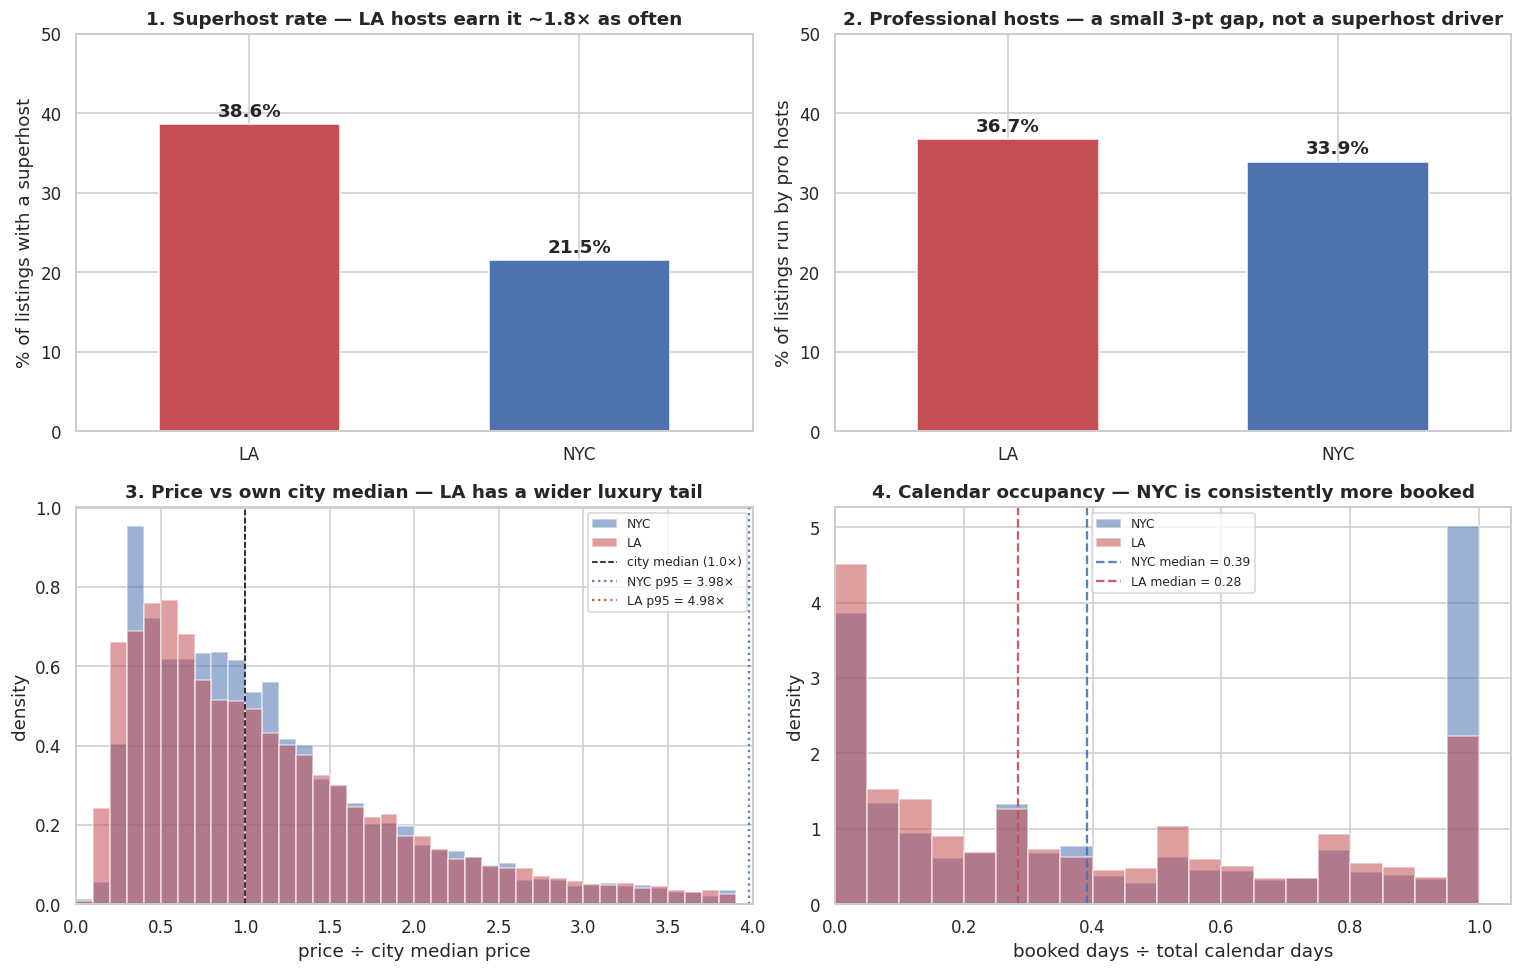

SUMMARY STATS BACKING EACH INSIGHT

1. Superhost rate by city (%):
city
LA     38.64
NYC    21.51

2. Professional-host rate by city (%):
city
LA     36.73
NYC    33.89

3. price ÷ city median — mean, p95 by city:
       mean  median    p95
city                      
LA    1.549     1.0  4.982
NYC   1.423     1.0  3.978

4. Calendar occupancy — mean, median by city:
       mean  median
city               
LA    0.387   0.285
NYC   0.479   0.392

LEAD INSIGHT — The superhost paradox
LA has 38.6% superhosts (NYC: 21.5%),
yet NYC listings are MORE booked (median 0.39 vs LA 0.28).
→ Superhost status is a quality signal, not a demand signal.


In [35]:
# =========================================================
# 4.5 INSIGHTS — four non-obvious findings
# =========================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# ---------------------------------------------------------
# INSIGHT 1 — LA hosts earn superhost ~1.8× as often
# ---------------------------------------------------------
sh = (listings.dropna(subset=["host_is_superhost"])
              .groupby("city", observed=True)["host_is_superhost"]
              .mean().mul(100))

ax = axes[0, 0]
sh.plot(kind="bar", ax=ax, color=["#C44E52", "#4C72B0"], width=0.55)
ax.set_title("1. Superhost rate — LA hosts earn it ~1.8× as often")
ax.set_ylabel("% of listings with a superhost")
ax.set_xlabel("")
ax.set_ylim(0, 50)
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(sh.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

# ---------------------------------------------------------
# INSIGHT 2 — LA has a slightly larger professional-host share
# ---------------------------------------------------------
ph = (listings.dropna(subset=["is_professional_host"])
              .groupby("city", observed=True)["is_professional_host"]
              .mean().mul(100))

ax = axes[0, 1]
ph.plot(kind="bar", ax=ax, color=["#C44E52", "#4C72B0"], width=0.55)
ax.set_title("2. Professional hosts — a small 3-pt gap, not a superhost driver")
ax.set_ylabel("% of listings run by pro hosts")
ax.set_xlabel("")
ax.set_ylim(0, 50)
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(ph.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

# ---------------------------------------------------------
# INSIGHT 3 — LA has fatter price tails (after city normalisation)
# ---------------------------------------------------------
ax = axes[1, 0]
p95_vals = {}
for city, colour in [("NYC", "#4C72B0"), ("LA", "#C44E52")]:
    subset = listings.loc[listings["city"] == city,
                          "price_vs_city_median"].dropna()
    ax.hist(subset, bins=np.arange(0, 4, 0.1),
            alpha=0.55, label=city, color=colour, density=True)
    p95_vals[city] = subset.quantile(0.95)

ax.axvline(1.0, color="black", linestyle="--", linewidth=1,
           label="city median (1.0×)")
ax.axvline(p95_vals["NYC"], color="#4C72B0", linestyle=":",
           linewidth=1.5, alpha=0.9,
           label=f"NYC p95 = {p95_vals['NYC']:.2f}×")
ax.axvline(p95_vals["LA"], color="#C44E52", linestyle=":",
           linewidth=1.5, alpha=0.9,
           label=f"LA p95 = {p95_vals['LA']:.2f}×")

ax.set_title("3. Price vs own city median — LA has a wider luxury tail")
ax.set_xlabel("price ÷ city median price")
ax.set_ylabel("density")
ax.set_xlim(0, 4)
ax.legend(fontsize=8, loc="upper right")

# ---------------------------------------------------------
# INSIGHT 4 — The superhost paradox: NYC is more booked
#             despite fewer superhosts
# ---------------------------------------------------------
ax = axes[1, 1]
med_vals = {}
for city, colour in [("NYC", "#4C72B0"), ("LA", "#C44E52")]:
    subset = listings.loc[listings["city"] == city,
                          "cal_occupancy_rate"].dropna()
    ax.hist(subset, bins=np.arange(0, 1.05, 0.05),
            alpha=0.55, label=city, color=colour, density=True)
    med_vals[city] = subset.median()

for city, colour in [("NYC", "#4C72B0"), ("LA", "#C44E52")]:
    ax.axvline(med_vals[city], color=colour, linestyle="--",
               linewidth=1.5, alpha=0.9,
               label=f"{city} median = {med_vals[city]:.2f}")

ax.set_title("4. Calendar occupancy — NYC is consistently more booked")
ax.set_xlabel("booked days ÷ total calendar days")
ax.set_ylabel("density")
ax.set_xlim(0, 1.05)
ax.legend(fontsize=8, loc="upper center")

plt.tight_layout()
plt.savefig("/work/insight_4panel.png", dpi=110, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------
# SUMMARY STATS — the numbers behind each insight
# ---------------------------------------------------------
print("=" * 65)
print("SUMMARY STATS BACKING EACH INSIGHT")
print("=" * 65)

print("\n1. Superhost rate by city (%):")
print(sh.round(2).to_string())

print("\n2. Professional-host rate by city (%):")
print(ph.round(2).to_string())

print("\n3. price ÷ city median — mean, p95 by city:")
stats3 = (listings.groupby("city", observed=True)["price_vs_city_median"]
                  .agg(mean="mean", median="median",
                       p95=lambda s: s.quantile(0.95))
                  .round(3))
print(stats3.to_string())

print("\n4. Calendar occupancy — mean, median by city:")
stats4 = (listings.groupby("city", observed=True)["cal_occupancy_rate"]
                  .agg(mean="mean", median="median")
                  .round(3))
print(stats4.to_string())

# Lead insight framing
print("\n" + "=" * 65)
print("LEAD INSIGHT — The superhost paradox")
print("=" * 65)
print(f"LA has {sh['LA']:.1f}% superhosts (NYC: {sh['NYC']:.1f}%),")
print(f"yet NYC listings are MORE booked "
      f"(median {stats4.loc['NYC','median']:.2f} vs LA "
      f"{stats4.loc['LA','median']:.2f}).")
print("→ Superhost status is a quality signal, not a demand signal.")

In [51]:
# re-save cleaning log and download manually
cleaning_log = pd.DataFrame(log_nyc + log_la)
cleaning_log.to_csv("/work/cleaning_log_4_2.csv", index=False)
print(f"Saved {len(cleaning_log)} entries")

Saved 50 entries


4\.6 Machine Learning
• Frame at least one ML task on the wrangled dataset — classification, regression, clustering, or 
forecasting, whichever fits the data and question\.
• Justify the model choice\(s\); compare at least two algorithms or one algorithm against a simple baseline\.
• Follow proper methodology: train/test \(or train/validation/test\) split, appropriate preprocessing 
\(scaling/encoding\) fit only on training data, and cross\-validation where feasible\.
• Report evaluation metrics appropriate to the task \(e\.g\. accuracy/precision/recall/F1/ROC\-AUC for 
classification; RMSE/MAE/R² for regression\) and interpret them honestly, including where the model 
underperforms\.

4\.7 Power BI Dashboard
• Build a Power BI \(\.pbix\) dashboard connected to the wrangled dataset and, where relevant, model 
outputs \(e\.g\. predicted vs\. actual, cluster labels, forecast bands\)\.
• Minimum 3 report pages/tabs: an overview page, a detail/drill\-down page, and a model\-insights page\.
• Include at least one interactive element \(slicer, filter, drill\-through\) and use visuals appropriate to each 
insight rather than defaulting to bar charts throughout\.
• Dashboard should tell a coherent story for a non\-technical stakeholder title, labels, and a brief 
narrative/annotation, not just raw charts\.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=b08d51f8-f494-4c48-ae3b-c4c2b50e7e87' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>